In [18]:
import json
import os
import random

import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

In [33]:
# Function to parse the XML file and merge bounding boxes and points with the same ID
def parse_and_merge_annotations(xml_file):
    tree = ET.parse(xml_file)
    root = tree.getroot()
    
    annotations = {}
    
    for image in root.findall('image'):
        image_id = image.get('id')
        image_name = image.get('name')
        width = int(image.get('width'))
        height = int(image.get('height'))
        
        annotations[image_name] = {
            'width': width,
            'height': height,
            'objects': []
        }
        
        boxes = {}
        points = {}
        
        for box in image.findall('box'):
            obj_id = box.find("attribute[@name='ID']").text
            if obj_id not in boxes:
                boxes[obj_id] = []
            boxes[obj_id].append(box)
        
        for point in image.findall('points'):
            obj_id = point.find("attribute[@name='ID']").text
            if obj_id not in points:
                points[obj_id] = []
            points[obj_id].append(point)
        
        for obj_id in boxes:
            if obj_id in points:
                for box in boxes[obj_id]:
                    for point in points[obj_id]:
                        annotations[image_name]['objects'].append({
                            'label': box.get('label'),
                            'bounding_box': [
                                float(box.get('xtl')),
                                float(box.get('ytl')),
                                float(box.get('xbr')),
                                float(box.get('ybr'))
                            ],
                            'points': [
                                (float(p.split(',')[0]), float(p.split(',')[1])) for p in point.get('points').split(';')
                            ],
                            'color': (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))
                        })
    
    return annotations

# Function to draw annotations on the image
def draw_annotations(image_path, annotations):
    image = Image.open(image_path)
    draw = ImageDraw.Draw(image)
    
    for obj in annotations['objects']:
        label = obj['label']
        bounding_box = obj['bounding_box']
        points = obj['points']
        color = obj['color']
        
        draw.rectangle(bounding_box, outline=color, width=2)
        for p in points:
            draw.ellipse([p[0]-3, p[1]-3, p[0]+3, p[1]+3], fill=color)
    
    return image

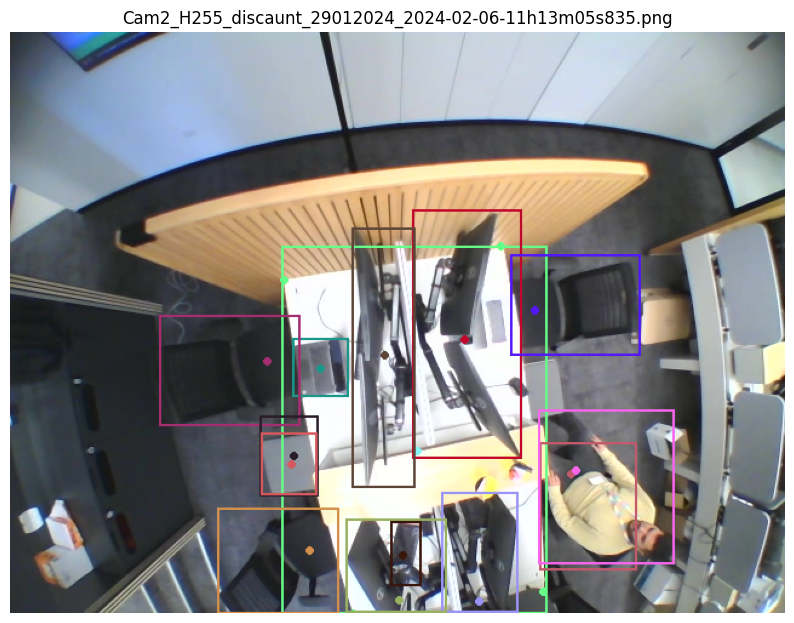

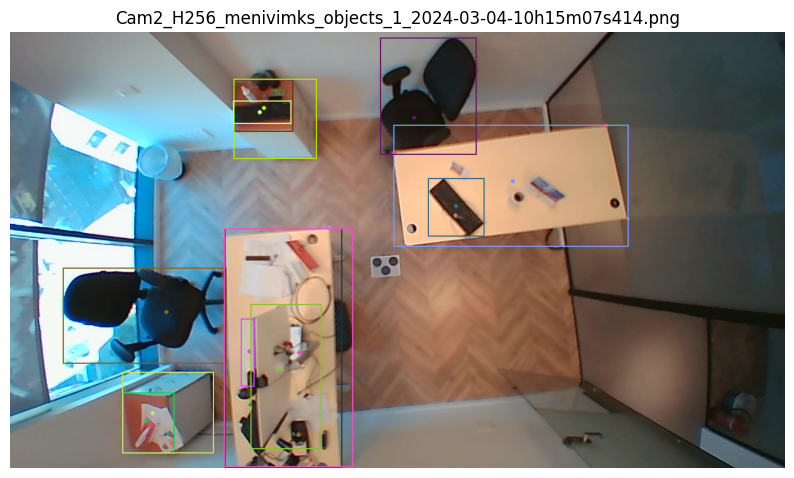

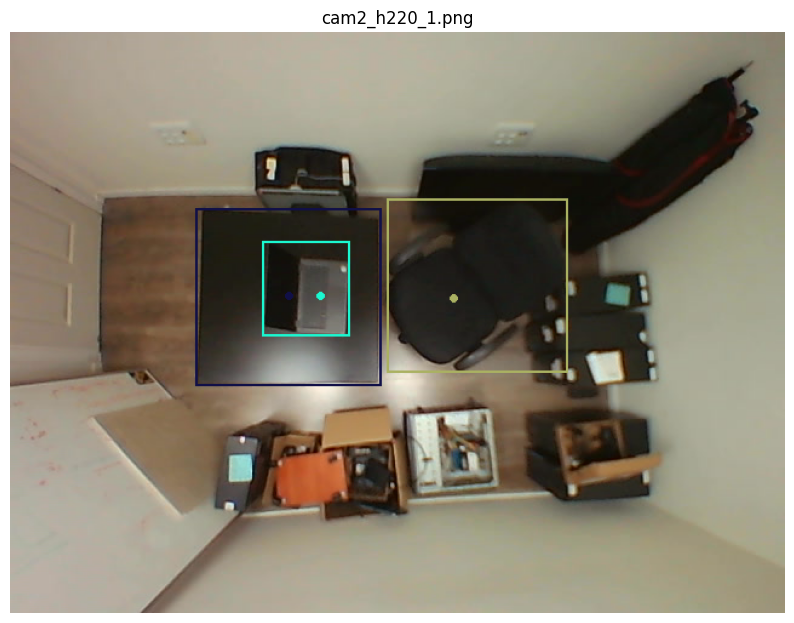

In [36]:
annotations = parse_and_merge_annotations("3images/annotations.xml")
    
for image_name, annotation in annotations.items():
    image_path = os.path.join("3images", image_name)  # Adjust this if images are in a different directory
    annotated_image = draw_annotations(image_path, annotation)
    
    plt.figure(figsize=(10, 10))
    plt.imshow(annotated_image)
    plt.title(image_name)
    plt.axis('off')
    plt.show()

In [37]:
annotations["cam2_h220_1.png"]

{'width': 640,
 'height': 480,
 'objects': [{'label': 'Desk',
   'bounding_box': [153.0, 146.29, 306.24, 292.31],
   'points': [(230.2, 218.2)],
   'color': (17, 16, 71)},
  {'label': 'Laptop (open)',
   'bounding_box': [208.6, 173.96, 280.26, 251.3],
   'points': [(256.2, 218.0)],
   'color': (27, 247, 208)},
  {'label': 'Office chair',
   'bounding_box': [311.06, 138.38, 460.4, 281.78],
   'points': [(366.86, 220.93)],
   'color': (170, 177, 98)}]}